In [1]:
# imports
import numpy as np

In [2]:
# ex 1
def soft_thresholding(Y, tau):
    U, s, Vt = np.linalg.svd(Y, full_matrices=False)

    s = np.maximum(s - tau, 0)

    return (U * s) @ Vt

def SVT(tau, delta, Omega, P_Omega_M, maxit, tol):

    Y = np.zeros_like(P_Omega_M, dtype=float)
    resvec = []

    norm_M = np.linalg.norm(P_Omega_M, "fro")

    if norm_M == 0:
        return Y, np.array([0.0])

    for k in range(maxit):
        X = soft_thresholding(Y, tau)

        R = P_Omega_M - np.where(Omega, X, 0)

        # Calculate the relative residual
        res = np.linalg.norm(R, "fro") / norm_M
        resvec.append(res)

        # Stopping criterion
        if res <= tol:
            break

        Y = Y + delta * R
    
    return X, resvec

In [3]:
M = np.array([
    [4.0, 2.0],
    [2.0, 1.0]
])

Omega = np.array([
    [True, True],
    [True, False]
])

P_Omega_M = np.where(Omega, M, 0)

X, resvec = SVT(
    tau=10,
    delta=1.2,
    Omega=Omega,
    P_Omega_M=P_Omega_M,
    maxit=1000,
    tol=1e-6
)

print("Original matrix:\n", M)
print("Observed matrix:\n", P_Omega_M)
print("Recovered matrix:\n", X)
print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])

Original matrix:
 [[4. 2.]
 [2. 1.]]
Observed matrix:
 [[4. 2.]
 [2. 0.]]
Recovered matrix:
 [[4.00000231 1.99999753]
 [1.99999753 0.99999695]]
Iterations: 51
Final residual: 8.559162059652203e-07


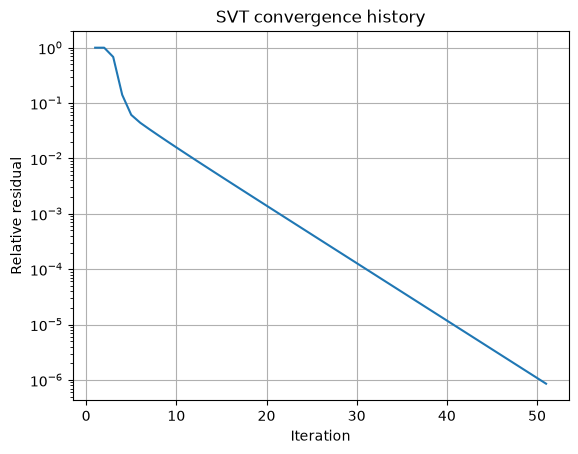

In [4]:
import matplotlib.pyplot as plt

plt.semilogy(
    range(1, len(resvec) + 1),
    resvec
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT convergence history")
plt.grid(True)
plt.show()